
# Lab 8: The Quantum Fourier Transform - The Heart of Quantum Algorithms

Welcome to Lab 8! In our journey so far, we have explored several powerful quantum algorithms like Deutsch-Jozsa and Grover's search. These algorithms solve specific problems faster than their classical counterparts. Now, we will shift our focus to one of the most important and fundamental tools in the quantum computing toolkit: the **Quantum Fourier Transform (QFT)**.

The QFT is the quantum analogue of the classical Discrete Fourier Transform (DFT), a ubiquitous tool in classical signal processing, data analysis, and engineering. Just as the DFT decomposes a signal into its constituent frequencies, the QFT transforms a quantum state from the computational basis (e.g., `|011>`) into the Fourier basis, which reveals information about the state's phase.

Unlike the algorithms we've seen before, the QFT is not typically used as a standalone algorithm to solve a problem. Instead, it serves as a crucial subroutine—a powerful building block—at the core of many of the most famous quantum algorithms, including **Shor's algorithm** for factoring integers and the **quantum phase estimation** algorithm. Its ability to efficiently analyze the periodic properties of quantum states is what unlocks their incredible power.

In this lab, we will:
*   Implement the Quantum Fourier Transform (QFT) circuit from scratch, understanding its construction from Hadamard gates and a series of controlled phase rotations.
*   Build the QFT step-by-step, including the final SWAP operations required to order the qubits correctly.
*   Apply our QFT implementation to various input states, such as the ground state `|000>` and an encoded integer state like `|101>`.
*   Use the **`statevector_simulator`** to inspect the resulting quantum state and visualize the transformation into the Fourier basis.
*   Construct and apply the inverse QFT to transform a state back from the Fourier basis to the computational basis, demonstrating that the process is reversible.
*   Appreciate the role of the QFT as an essential primitive for more advanced quantum algorithms that rely on phase and period finding.

Let's delve into this essential quantum subroutine and unlock the tools needed for some of the most powerful quantum algorithms ever conceived.

The quantum Fourier transform (QFT) is the quantum implementation of the discrete Fourier transform over the amplitudes of a wavefunction. It is part of many quantum algorithms, most notably Shor's factoring algorithm and quantum phase estimation.

The quantum Fourier transform (QFT) transforms between two bases, the computational (Z) basis, and the Fourier basis. The H-gate is the single-qubit QFT, and it transforms between the Z-basis states |0⟩ and |1⟩ to the X-basis states |+⟩ and |−⟩. In the same way, all multi-qubit states in the computational basis have corresponding states in the Fourier basis. The QFT is simply the function that transforms between these bases.

In [ ]:
# import image module
from IPython.display import Image

# get the image
Image(url="qft.png")

**Remember that Qiskit's least significant bit has the lowest index (0) means q2 has 0 index (little endian ordering), thus the circuit will be mirrored through the horizontal in relation to the above circuit image. Note that UROT is also known as CROT which means Controlled Rotations or Controlled Phasing (CP). Also note that interchanging the CP gates does not affect the output of the circuit.**

In [ ]:
import qiskit
from qiskit import QuantumCircuit, transpile, QuantumRegister, ClassicalRegister
from qiskit_aer import AerSimulator, Aer
from qiskit.visualization import plot_histogram
import matplotlib
from math import pi, sqrt # pi = 3.14 and square root operation
from qiskit.visualization import plot_state_city # Density Matrix plot
from qiskit.visualization import plot_state_qsphere # used for multi qubit visualisation
from qiskit.visualization import plot_bloch_multivector # Plotting the Bloch Sphere for Single Qubits
from qiskit.visualization import plot_histogram # 2D Histogram Plotting
import numpy as np # Numerical Python Library
from qiskit.quantum_info import Operator
from qiskit.circuit.library import ZGate


## Defining the QFT Function

In [ ]:
# Function to compute the QFT

def qft_rotations(circuit, n):
    if n == 0: # Exit function if circuit is empty
        return circuit
    n -= 1 # Indexes start from 0
    circuit.h(n) # Apply the H-gate to the most significant qubit
    for qubit in range(n):
        # For each less significant qubit, we need to do a
        # smaller-angled controlled rotation:
        circuit.cp(pi/2**(n-qubit), qubit, n)

    qft_rotations(circuit, n)

## Visualizing 3 Qubit QFT Circuit

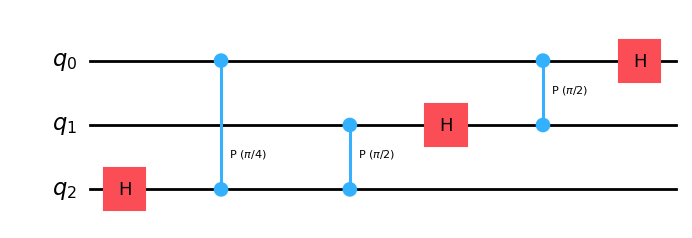

In [ ]:
qc = QuantumCircuit(3)
qft_rotations(qc,3)
qc.draw('mpl')

## Function to SWAP Registers after QFT Computation

In [ ]:
# Function to SWAP the registers as seen in lecture
def swap_registers(circuit, n):
    for qubit in range(n//2):
        circuit.swap(qubit, n-qubit-1)
    return circuit

## QFT Function

In [ ]:
# Function to apply the QFT to the Quantum Circuit
def qft(circuit, n):
    """QFT on the first n qubits in circuit"""
    qft_rotations(circuit, n)
    swap_registers(circuit, n)
    return circuit

## QFT|000>

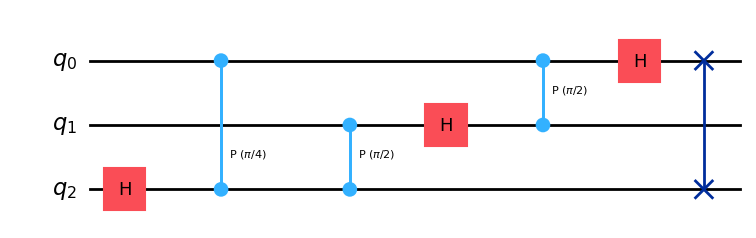

In [ ]:
# QFT circuit for a 3 Qubit case at state |000>
qc = QuantumCircuit(3)
qft(qc,3)
qc.draw('mpl')

## Visualzing the QFT results using Bloch Sphere


Quantum state is: Statevector([0.354+0.j, 0.354+0.j, 0.354+0.j, 0.354+0.j, 0.354+0.j,
             0.354+0.j, 0.354+0.j, 0.354+0.j],
            dims=(2, 2, 2))


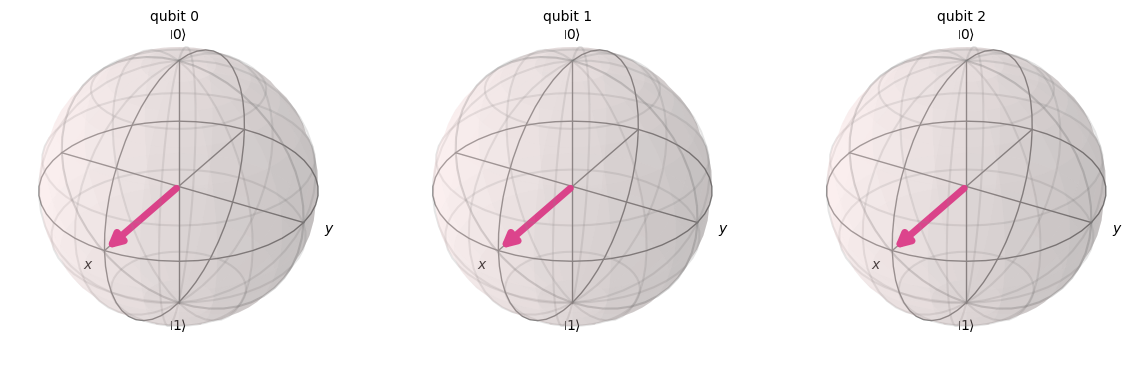

In [ ]:
# Let's see the result

# To get the eigenvector you should use the statevector simulator in the core of the circuit (without measurements)
backend = Aer.get_backend('statevector_simulator')

transpiled_qc = transpile(qc, backend)

# Execute the circuit
result = backend.run(transpiled_qc).result().get_statevector(transpiled_qc, decimals=3)

# Printing the state
print("\nQuantum state is:",result)

# Plotting the Bloch Sphere
plot_bloch_multivector(result)

The state received above is $QFT|000> = |+++>$

## QFT|101>

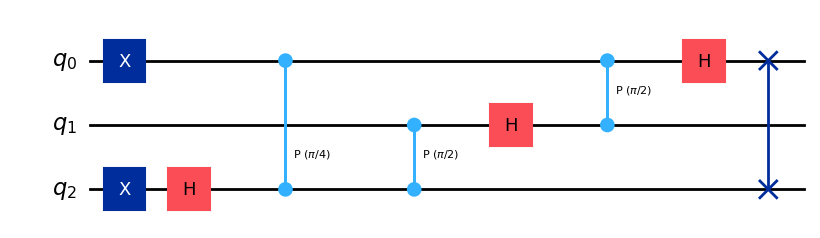

In [ ]:
# Circuit for a 3 Qubit QFT
qc = QuantumCircuit(3)

# Encode the state 5 - |101>
qc.x(0)
qc.x(2)

# Applying the QFT to the circuit with input as |101>
qft(qc,3)
qc.draw('mpl')


Quantum state is: Statevector([ 0.354-0.j   , -0.25 -0.25j ,  0.   +0.354j,  0.25 -0.25j ,
             -0.354+0.j   ,  0.25 +0.25j , -0.   -0.354j, -0.25 +0.25j ],
            dims=(2, 2, 2))


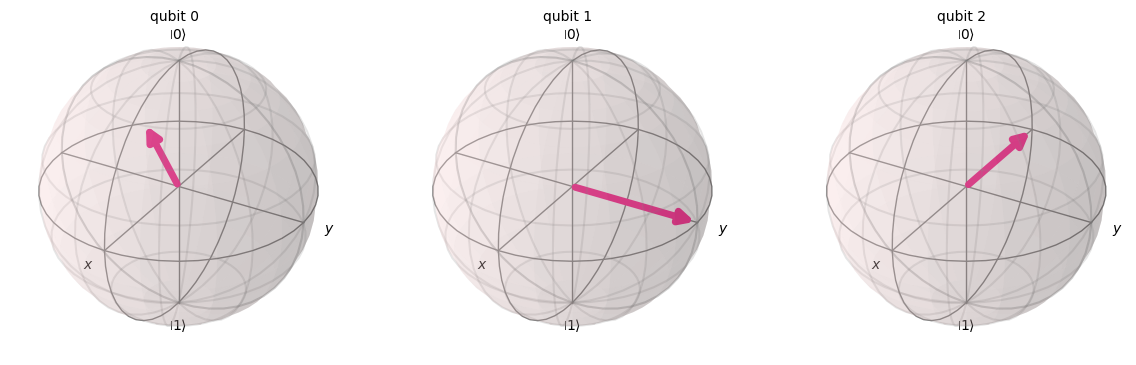

In [ ]:
# Let's see the result

# To get the eigenvector you should use the statevector simulator in the core of the circuit (without measurements)
backend = Aer.get_backend('statevector_simulator')

transpiled_qc = transpile(qc, backend)

# Execute the circuit
result = backend.run(qc).result().get_statevector(qc, decimals=3)

# Printing the state
print("\nQuantum state is:",result)

# Plotting the Bloch Sphere
plot_bloch_multivector(result)

The state $|\widetilde{5}>$ which we have received in the above diagram is the QFT of $|5> = |101>$ and comparing this state with the $QFT|000> = |+++>$, it can be seen that qubit 0 has $\frac{5}{8}$ of full turn, qubit 1 has $\frac{1}{4}$ of full turn and qubit 2 has $\frac{1}{2} $ of full turn as seen in the theory lectures.

## Inverse Quantum Fourier Transform

We create the state $|\widetilde{5}>$ and run the QFT in reverse. Finally we verify that the output is the state $|5⟩ = |101>$ as expected.

In [ ]:
def inverse_qft(circuit, n):
    """Does the inverse QFT on the first n qubits in circuit"""
    # First we create a QFT circuit of the correct size:
    qft_circ = qft(QuantumCircuit(n), n)
    # Then we take the inverse of this circuit
    invqft_circ = qft_circ.inverse()
    # And add it to the first n qubits in our existing circuit
    circuit.append(invqft_circ, circuit.qubits[:n])
    return circuit.decompose() # .decompose() allows us to see the individual gates

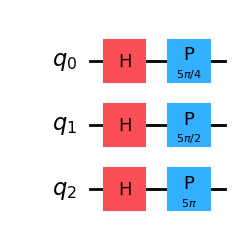

In [ ]:
# Creating the QFT|101> state manually
nqubits = 3
number = 5
qc = QuantumCircuit(nqubits)
for qubit in range(nqubits):
    qc.h(qubit)
qc.p(number*pi/4,0)
qc.p(number*pi/2,1)
qc.p(number*pi,2)

qc.draw('mpl')


Quantum state is: Statevector([ 0.354+0.j   , -0.25 -0.25j ,  0.   +0.354j,  0.25 -0.25j ,
             -0.354+0.j   ,  0.25 +0.25j , -0.   -0.354j, -0.25 +0.25j ],
            dims=(2, 2, 2))


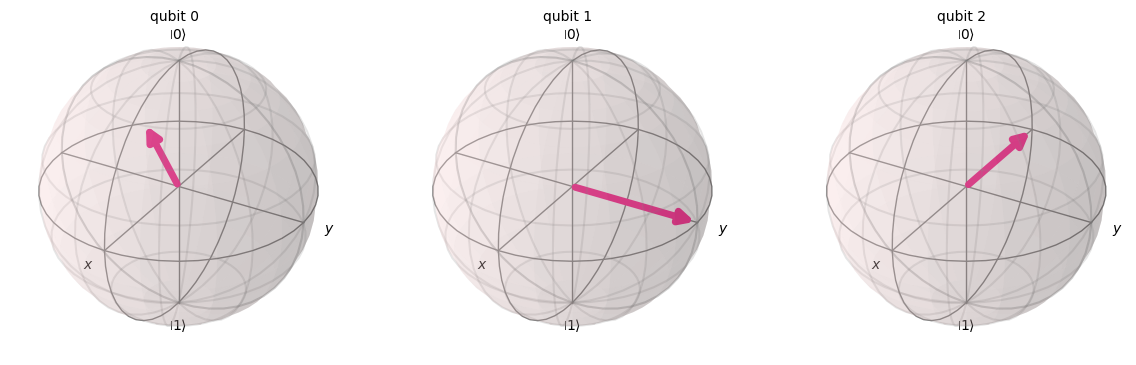

In [ ]:
# Let's see the result of QFT|101>

# To get the eigenvector you should use the statevector simulator in the core of the circuit (without measurements)
backend = Aer.get_backend('statevector_simulator')

transpiled_qc = transpile(qc, backend)

# Execute the circuit
result = backend.run(qc).result().get_statevector(qc, decimals=3)

# Printing the state
print("\nQuantum state is:",result)

# Plotting the Bloch Sphere
plot_bloch_multivector(result)

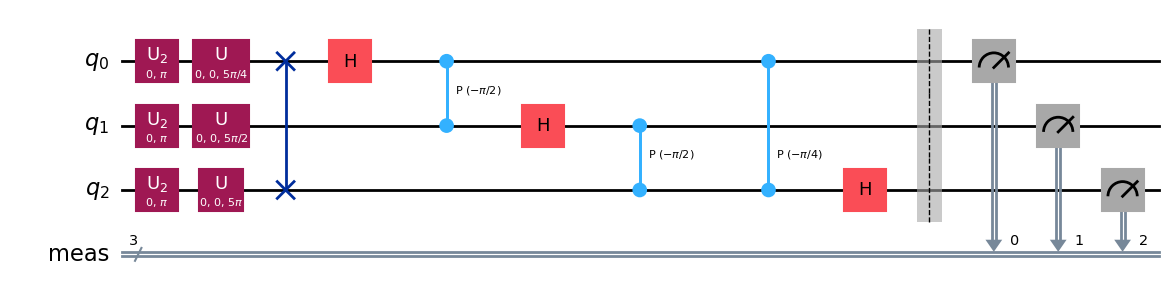

In [ ]:
# Calling the inverse QFT Function
qc = inverse_qft(qc, nqubits)
qc.measure_all()
qc.draw('mpl')


Total counts are: {'101': 1000}


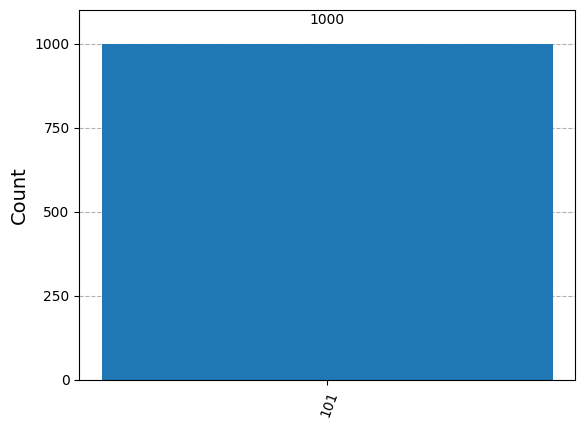

In [ ]:
# Use Aer's qasm_simulator
backend = Aer.get_backend('qasm_simulator')

transpiled_qc = transpile(qc, backend)

# Execute the circuit on the qasm simulator
job = backend.run(qc, shots=1000)

# Grab results from the job
result = job.result()

# Returns counts
counts = result.get_counts(qc)
print("\nTotal counts are:",counts)

# Plot the histogram
plot_histogram(counts)

As expected, we are able to get the state |101> which is number 5 in decimal.